In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import pandas as pd
from tca_openflux import TCA_OpenFLux, objective_wssr, objective_clr_wssr, flux_vector, calc_ci
from emu_example import closure, clr_func, clr_inv_func

import optimistix
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

In [2]:
def fva(parameters: dict[str, float]) -> dict:
    v_free = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
    # The free fluxes are split into fixed fluxes and parameters, where parameters are the one being estimated. 
    fixed_keys = ["v1", "v16", "v17", "v18", "v19", "v20"]
    fixed = {k: v_free[k] for k in fixed_keys}

    # We calculate the true data (MIDs)
    true_data = TCA_OpenFLux(parameters=parameters, fixed=fixed)

    key = jax.random.PRNGKey(1234)
    sims = 1000

    total_mol = 1e5
    total_isos = jax.tree.map(lambda x: x * total_mol, true_data)
    cv = 0.1
    norm_sigma_cv = jax.tree.map(lambda x: x * cv, total_isos)

    key, key_sim = jax.random.split(key)
    # We assume the absolute abandance to be independent normal distributions. 
    norm_sim = jax.tree.map(
        lambda mean, sigma: mean + sigma * jax.random.normal(key_sim, (sims, mean.shape[0])),
        total_isos,
        norm_sigma_cv,
    )

    # Simulated absolute abandance are closed to 1 to make relative abundance
    iso_proportions = jax.tree.map(
        lambda mat: closure(mat),
        norm_sim,
    )

    # We calculate the mean of the relative abundances. 
    mean_sim = jax.tree.map(
        lambda x: jnp.mean(x, axis=0),  # mean over isotopolouges
        iso_proportions
    )
    # and the standard deviation
    std_sim = jax.tree.map(
        lambda x: jnp.std(x, axis=0),  # standard deviation over isotopolouges
        iso_proportions
    )

    # and compute a covariance matrix
    D_sim = jax.tree.map(
        lambda x: jnp.diag(x), 
        std_sim
    )

    # We specify the solver and initial parameters
    solver = optimistix.BFGS(
        rtol=1e-12, atol=1e-12, verbose=frozenset({"step"})
    )

    init_params = {
        "v8": 0.2,
        "v2": 0.2,
        "v9": 0.3,
    }

    result_optimistix = optimistix.minimise(objective_wssr, y0=init_params, args=(mean_sim, D_sim, fixed), solver=solver, max_steps=10000)

    # CLR
    iso_clr = jax.tree.map(
        lambda x: clr_func(x),
        iso_proportions
    )

    mean_clr = jax.tree.map(
        lambda x: jnp.mean(x, axis=0),  # mean over bins
        iso_clr
    )

    std_clr = jax.tree.map(
        lambda x: jnp.std(x, axis=0),  # mean over isotopolouges
        iso_clr
    )

    D_clr = jax.tree.map(
        lambda x: jnp.diag(x), 
        std_clr
    )

    result_optimistix_clr = optimistix.minimise(objective_clr_wssr, y0=init_params, args=(mean_clr, D_clr, fixed), solver=solver, max_steps=10000)

    # Convert true MIDs to plain numpy for storage
    true_mids = {k: np.array(v) for k, v in true_data.items()}

    return {"Euclidean": result_optimistix.value, "Aitchison": result_optimistix_clr.value, "true_mids": true_mids}

In [3]:
parameters = {"v8": [0.200, 0.210, 0.220], "v2": [0.190, 0.20, 0.210], "v9": [0.190, 0.20, 0.210]}
v_true_dict = []
v_est_dict = []
v_clr_dict = []
for param_set in (
    dict(zip(parameters, values))
    for values in zip(*parameters.values())
):
    v_true_dict.append(param_set) 
    v_est_dict.append(fva(param_set)["Euclidean"])
    v_clr_dict.append(fva(param_set)["Aitchison"])

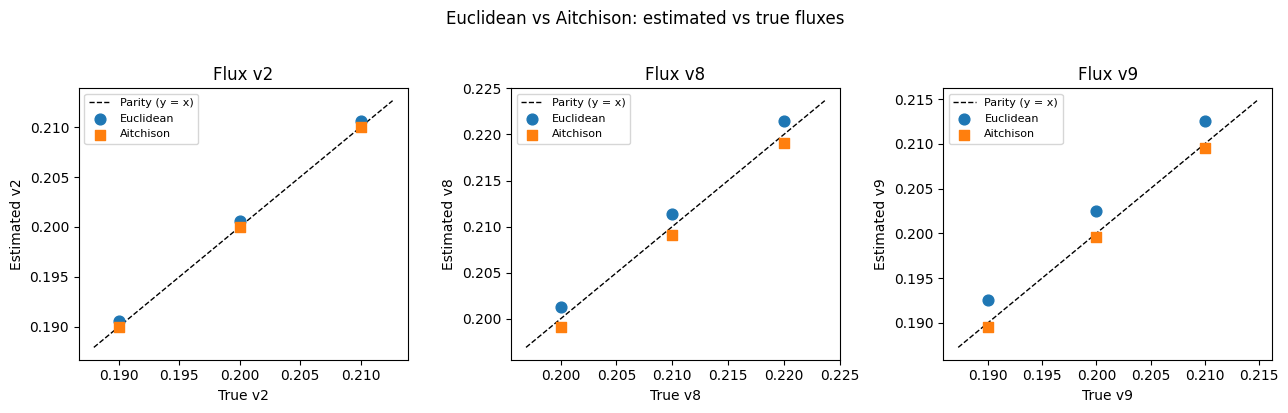

In [4]:
flux_vars = ["v2", "v8", "v9"]

# Extract arrays: true, euclidean estimated, aitchison estimated
true_vals  = {v: np.array([d[v] for d in v_true_dict]) for v in flux_vars}
euc_vals   = {v: np.array([float(d[v]) for d in v_est_dict]) for v in flux_vars}
ait_vals   = {v: np.array([float(d[v]) for d in v_clr_dict]) for v in flux_vars}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, v in zip(axes, flux_vars):
    t = true_vals[v]
    e = euc_vals[v]
    a = ait_vals[v]

    # parity line spanning the full range of values shown
    all_vals = np.concatenate([t, e, a])
    lo, hi = all_vals.min(), all_vals.max()
    pad = (hi - lo) * 0.1
    parity = np.array([lo - pad, hi + pad])
    ax.plot(parity, parity, "k--", lw=1, label="Parity (y = x)")

    ax.scatter(t, e, marker="o", s=60, label="Euclidean", zorder=3)
    ax.scatter(t, a, marker="s", s=60, label="Aitchison", zorder=3)

    ax.set_xlabel(f"True {v}")
    ax.set_ylabel(f"Estimated {v}")
    ax.set_title(f"Flux {v}")
    ax.legend(fontsize=8)

fig.suptitle("Euclidean vs Aitchison: estimated vs true fluxes", y=1.02)
fig.tight_layout()
plt.show()


In [5]:
# ---------------------------------------------------------------------------
# Batch run: load the 30 LHS samples produced by flux_range.ipynb
# ---------------------------------------------------------------------------
flux_df = pd.read_csv("flux_sampling/flux_samples_R2_R8_R9.csv", index_col="Sample")
print(f"Loaded {len(flux_df)} flux combinations:")
print(flux_df.round(4))

batch_true      = []
batch_euc       = []
batch_ait       = []
batch_true_mids = []

for sample_id, row in flux_df.iterrows():
    # R2/R8/R9 are already ÷ 1000, so they map directly to v2/v8/v9
    params = {"v2": float(row["R2"]), "v8": float(row["R8"]), "v9": float(row["R9"])}
    result = fva(params)
    batch_true.append(params)
    batch_euc.append(result["Euclidean"])
    batch_ait.append(result["Aitchison"])
    batch_true_mids.append(result["true_mids"])

print(f"\nFinished {len(batch_true)} runs.")

Loaded 50 flux combinations:
            R2      R8      R9
Sample                        
1       0.1600  0.7312  0.1503
2       0.2199  0.2381  0.2633
3       0.1204  0.2643  0.2387
4       0.0300  0.1126  0.0008
5       0.2533  0.6635  0.4409
6       0.2956  0.3889  0.4681
7       0.0672  0.0074  0.3230
8       0.0835  0.8006  0.4129
9       0.3250  0.7961  0.4864
10      0.0063  0.6169  0.5640
11      0.1866  0.3206  0.0306
12      0.3079  0.7706  0.3867
13      0.1114  0.8705  0.4548
14      0.1012  0.1513  0.1735
15      0.2991  0.0338  0.4251
16      0.3116  0.2923  0.5342
17      0.2794  0.1772  0.0892
18      0.1518  0.5243  0.0953
19      0.1274  0.7044  0.3607
20      0.0227  0.4972  0.5133
21      0.0550  0.5506  0.3709
22      0.0742  0.1873  0.4969
23      0.1350  0.5739  0.5257
24      0.2282  0.4757  0.2469
25      0.0472  0.6353  0.2967
26      0.0378  0.9541  0.2097
27      0.2604  0.3443  0.4727
28      0.2680  0.8237  0.1125
29      0.2442  0.9182  0.0375
30      0.

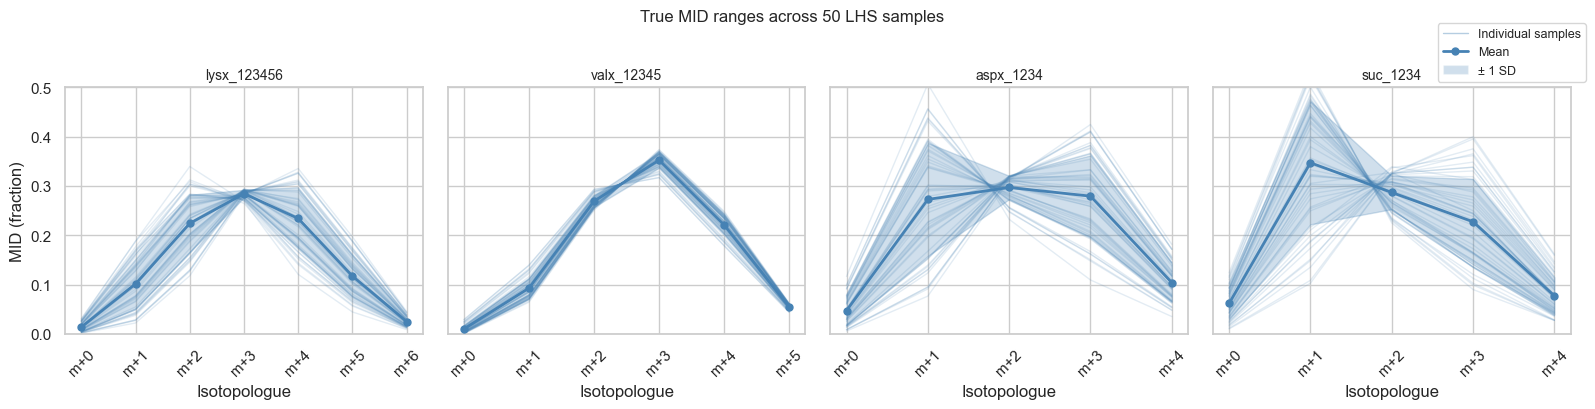

In [6]:
# ── Build tidy long-form DataFrame of true MIDs ─────────────────────────────
mid_records = []
mid_keys = list(batch_true_mids[0].keys())

for i, mids in enumerate(batch_true_mids):
    for key, values in mids.items():
        for iso_idx, val in enumerate(values):
            mid_records.append({
                "Sample":      i,
                "Metabolite":  key,
                "Isotopologue": f"m+{iso_idx}",
                "iso_idx":     iso_idx,
                "MID":         float(val),
            })

mid_df = pd.DataFrame(mid_records)

# ── Plot ─────────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="colorblind")

n_keys = len(mid_keys)
fig, axes = plt.subplots(1, n_keys, figsize=(4 * n_keys, 4), sharey=True)
fig.suptitle("True MID ranges across 50 LHS samples", fontsize=12, y=1.02)

for ax, key in zip(axes, mid_keys):
    sub = mid_df[mid_df["Metabolite"] == key].sort_values("iso_idx")

    # Individual sample lines — faint spaghetti to show spread
    for sample_id, grp in sub.groupby("Sample"):
        ax.plot(
            grp["Isotopologue"], grp["MID"],
            color="steelblue", alpha=0.15, lw=1, zorder=1,
        )

    # Mean ± 1 SD band on top
    stats_df = sub.groupby(["iso_idx", "Isotopologue"])["MID"].agg(
        mean="mean", std="std"
    ).reset_index().sort_values("iso_idx")

    ax.fill_between(
        stats_df["Isotopologue"],
        (stats_df["mean"] - stats_df["std"]).clip(lower=0),
        (stats_df["mean"] + stats_df["std"]).clip(upper=1),
        alpha=0.25, color="steelblue", zorder=2,
    )
    ax.plot(
        stats_df["Isotopologue"], stats_df["mean"],
        color="steelblue", lw=2, marker="o", ms=5, zorder=3, label="Mean",
    )

    ax.set_ylim(0, 0.5)
    ax.set_title(key, fontsize=10)
    ax.set_xlabel("Isotopologue")
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("MID (fraction)")

# Single legend for the whole figure
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
legend_handles = [
    Line2D([0], [0], color="steelblue", alpha=0.4, lw=1, label="Individual samples"),
    Line2D([0], [0], color="steelblue", lw=2, marker="o", ms=5, label="Mean"),
    Patch(facecolor="steelblue", alpha=0.25, label="± 1 SD"),
]
fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(1.0, 1.0), fontsize=9)

fig.tight_layout()
plt.show()

Outlier samples (IQR rule): [9, 19, 21, 24]  (4/50 removed)


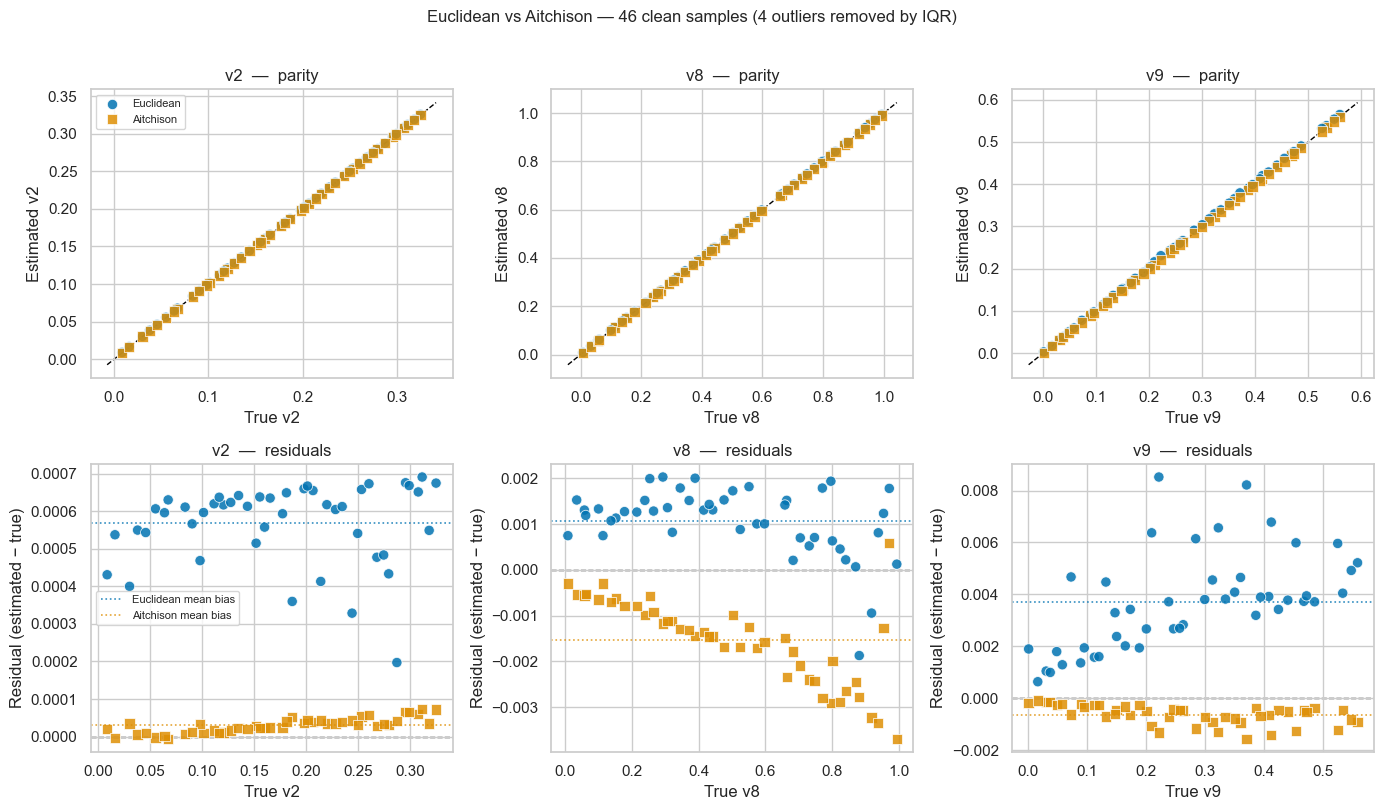


Summary statistics (46 clean samples):
                   Bias     MAE    RMSE
Flux Method                            
v2   Euclidean  0.00057 0.00057 0.00058
     Aitchison  0.00003 0.00003 0.00004
v8   Euclidean  0.00107 0.00119 0.00130
     Aitchison -0.00154 0.00156 0.00179
v9   Euclidean  0.00370 0.00370 0.00414
     Aitchison -0.00063 0.00063 0.00073

Outlier sample details (excluded):
Flux          v2                  v8                       v9          
Method Aitchison Euclidean Aitchison      Euclidean Aitchison Euclidean
Sample                                                                 
9       -0.00000  -0.16080  -0.00080  2804666.39170  -0.00360   1.64330
19      -0.00000   0.00060  -0.00090        0.00280  -0.00280   0.01610
21      -0.00000   0.00060  -0.00070        0.00140  -0.00180   0.00890
24      -0.00000  -0.21000  -0.00130 11697607.06650  -0.00140   1.40460


In [46]:
flux_vars = ["v2", "v8", "v9"]

true_arr = {v: np.array([d[v]        for d in batch_true]) for v in flux_vars}
euc_arr  = {v: np.array([float(d[v]) for d in batch_euc])  for v in flux_vars}
ait_arr  = {v: np.array([float(d[v]) for d in batch_ait])  for v in flux_vars}

# ── Build tidy long-form DataFrame ──────────────────────────────────────────
records = []
for i in range(len(batch_true)):
    for v in flux_vars:
        for method, arr in [("Euclidean", euc_arr), ("Aitchison", ait_arr)]:
            records.append({
                "Sample":    i,
                "Flux":      v,
                "Method":    method,
                "True":      true_arr[v][i],
                "Estimated": float(arr[v][i]),
                "Residual":  float(arr[v][i]) - true_arr[v][i],
            })

df = pd.DataFrame(records)

# ── IQR outlier detection (per flux, across both methods) ───────────────────
# Flag a sample if |residual| > Q3 + 1.5·IQR for *any* flux or method
abs_res = df.groupby("Sample")["Residual"].apply(lambda x: np.abs(x).max())
q1, q3  = abs_res.quantile(0.25), abs_res.quantile(0.75)
iqr     = q3 - q1
outlier_mask   = abs_res > q3 + 1.5 * iqr
outlier_samples = set(abs_res[outlier_mask].index.tolist())

df["Outlier"] = df["Sample"].isin(outlier_samples)
df_clean   = df[~df["Outlier"]]
df_outlier = df[df["Outlier"]]

n_out = len(outlier_samples)
print(f"Outlier samples (IQR rule): {sorted(outlier_samples)}  ({n_out}/{len(batch_true)} removed)")

# ── Plot ─────────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="colorblind")
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle(
    f"Euclidean vs Aitchison — {len(batch_true) - n_out} clean samples "
    f"({n_out} outlier{'s' if n_out != 1 else ''} removed by IQR)",
    fontsize=12, y=1.01,
)

for col, v in enumerate(flux_vars):
    sub = df_clean[df_clean["Flux"] == v]

    # ── Row 0: parity plot ───────────────────────────────────────────────────
    ax = axes[0, col]
    lo = min(sub["True"].min(), sub["Estimated"].min())
    hi = max(sub["True"].max(), sub["Estimated"].max())
    pad = (hi - lo) * 0.05
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad],
            color="black", lw=1, ls="--", zorder=0, label="y = x")
    sns.scatterplot(
        data=sub, x="True", y="Estimated",
        hue="Method", style="Method",
        markers={"Euclidean": "o", "Aitchison": "s"},
        s=55, alpha=0.85, ax=ax, legend=(col == 0),
    )
    ax.set_title(f"{v}  —  parity")
    ax.set_xlabel(f"True {v}")
    ax.set_ylabel(f"Estimated {v}")
    if col == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[1:], labels[1:], fontsize=8)   # drop the "y=x" handle

    # ── Row 1: residual plot ─────────────────────────────────────────────────
    ax = axes[1, col]
    ax.axhline(0, color="black", lw=1, ls="--", zorder=0)
    sns.scatterplot(
        data=sub, x="True", y="Residual",
        hue="Method", style="Method",
        markers={"Euclidean": "o", "Aitchison": "s"},
        s=55, alpha=0.85, ax=ax, legend=False,
    )
    # Mean-bias lines per method
    for method, colour in [("Euclidean", sns.color_palette("colorblind")[0]),
                            ("Aitchison", sns.color_palette("colorblind")[1])]:
        bias = sub.loc[sub["Method"] == method, "Residual"].mean()
        ax.axhline(bias, color=colour, lw=1.2, ls=":", alpha=0.8,
                   label=f"{method} mean bias")
    ax.set_title(f"{v}  —  residuals")
    ax.set_xlabel(f"True {v}")
    ax.set_ylabel("Residual (estimated − true)")
    if col == 0:
        ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

# ── Summary statistics (clean samples only) ───────────────────────────────────
rows = []
for v in flux_vars:
    for method in ["Euclidean", "Aitchison"]:
        err = df_clean.loc[(df_clean["Flux"] == v) & (df_clean["Method"] == method), "Residual"].values
        rows.append({
            "Flux": v, "Method": method,
            "Bias": float(err.mean()),
            "MAE":  float(np.abs(err).mean()),
            "RMSE": float(np.sqrt((err ** 2).mean())),
        })

summary = pd.DataFrame(rows).set_index(["Flux", "Method"])
pd.set_option("display.float_format", "{:.5f}".format)
print(f"\nSummary statistics ({len(batch_true) - n_out} clean samples):")
print(summary)

if n_out:
    print(f"\nOutlier sample details (excluded):")
    print(df_outlier.pivot_table(
        index="Sample", columns=["Flux", "Method"], values="Residual"
    ).round(4))

## Why do outlier samples produce extreme v8 errors under Euclidean distance?

### Root cause 1 — Succinate symmetry creates a flat Euclidean objective for v8

`v8` enters every EMU transition matrix with a **0.5 multiplier** (e.g. `A1` rows 6, 8, 11, 16; `A3` rows 3–4; `A4` row 1 in `tca_openflux.py`).  
These 0.5 terms encode the **symmetric scrambling of succinate**: because succinate has C₂ symmetry, carbons 1–2 and 3–4 are interchangeable, and the label information in the measured MIDs is halved.  
More critically, `v8` only appears in the steady-state EMU balance as the **ratio `v8 / (v6 + v8)`** (diagonal term `−v6−v8`, off-diagonal `v8`). At large v8 values (as sampled by LHS: v8 up to 1.0), this ratio saturates toward 1 and becomes insensitive to further increases in v8. The Euclidean WSSR objective therefore develops a **flat plateau** along the v8 axis, and BFGS drifts to an arbitrary value.

### Root cause 2 — Euclidean distance ignores the simplex geometry

MIDs are **compositions** (they sum to 1 and live on the simplex). The Euclidean WSSR treats them as unconstrained points in ℝⁿ.  
When some isotopologue fractions are near zero (which happens for extreme flux values), the variance-scaling in WSSR collapses those terms (σ ≈ 0 → down-weight → near-zero gradient). The optimizer loses signal precisely where the data would be most informative.

### Why Aitchison distance is more robust

The CLR transform maps the simplex to ℝⁿ via **log-ratios**, so a near-zero fraction (e.g. M+0 ≈ 0.01) maps to a large *negative* CLR value — not a small one. The Aitchison objective therefore maintains a strong gradient everywhere on the simplex, including near the boundary, which keeps BFGS anchored near the true v8.

### Additional analyses below

1. **Objective landscape** — 1-D slice of WSSR vs CLR-WSSR along the v8 axis for an outlier sample, directly showing the flat Euclidean plateau.  
2. **Recovery rate** — fraction of samples that recover the true flux within ±5 %, ±10 %, ±20 %.  
3. **Error correlation heatmap** — whether errors in v2/v8/v9 are correlated, exposing the joint identifiability structure.

Outlier sample 19: true params = {'v2': 0.0226561117032938, 'v8': 0.4972040600374468, 'v9': 0.5133102340790426}


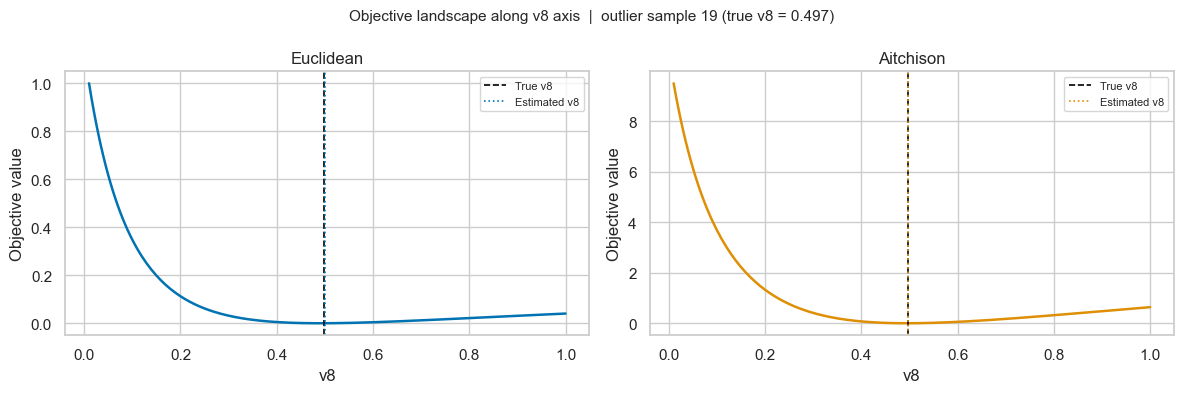

In [7]:
sns.set_theme(style="whitegrid", palette="colorblind")

fixed_keys = ["v1", "v16", "v17", "v18", "v19", "v20"]
v_free_ref  = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03,
               "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
fixed = {k: v_free_ref[k] for k in fixed_keys}

# ── Helper: simulate noisy MIDs for a given flux dict ────────────────────────
def simulate(params):
    true_data   = TCA_OpenFLux(parameters=params, fixed=fixed)
    total_isos  = jax.tree.map(lambda x: x * 1e5, true_data)
    cv_sigma    = jax.tree.map(lambda x: x * 0.1,  total_isos)
    key         = jax.random.PRNGKey(1234)
    _, key_sim  = jax.random.split(key)
    norm_sim    = jax.tree.map(
        lambda m, s: m + s * jax.random.normal(key_sim, (1000, m.shape[0])),
        total_isos, cv_sigma)
    iso_prop    = jax.tree.map(lambda x: closure(x), norm_sim)
    mean_s      = jax.tree.map(lambda x: jnp.mean(x, axis=0), iso_prop)
    std_s       = jax.tree.map(lambda x: jnp.std(x,  axis=0), iso_prop)
    D_s         = jax.tree.map(lambda x: jnp.diag(x), std_s)
    iso_clr     = jax.tree.map(clr_func, iso_prop)
    mean_clr    = jax.tree.map(lambda x: jnp.mean(x, axis=0), iso_clr)
    std_clr     = jax.tree.map(lambda x: jnp.std(x,  axis=0), iso_clr)
    D_clr       = jax.tree.map(lambda x: jnp.diag(x), std_clr)
    return mean_s, D_s, mean_clr, D_clr

# ═══════════════════════════════════════════════════════════════════════════════
# 1. OBJECTIVE LANDSCAPE — 1-D v8 slice for one outlier sample
# ═══════════════════════════════════════════════════════════════════════════════
# outlier_idx = min(outlier_samples, key=lambda i: batch_true[i]["v8"])
outlier_idx = 19
true_params = batch_true[outlier_idx]
print(f"Outlier sample {outlier_idx}: true params = {true_params}")

mean_s, D_s, mean_clr, D_clr = simulate(true_params)

v8_sweep = np.linspace(0.01, 1.0, 200)
wssr_vals, clr_vals = [], []
for v8_val in v8_sweep:
    p = {**true_params, "v8": float(v8_val)}
    wssr_vals.append(float(objective_wssr(p,     (mean_s,   D_s,   fixed))))
    clr_vals.append( float(objective_clr_wssr(p, (mean_clr, D_clr, fixed))))

landscape_df = pd.DataFrame({
    "v8":       np.concatenate([v8_sweep, v8_sweep]),
    "Objective": np.concatenate([wssr_vals, clr_vals]),
    "Method":   ["Euclidean"] * 200 + ["Aitchison"] * 200,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle(
    f"Objective landscape along v8 axis  |  outlier sample {outlier_idx} "
    f"(true v8 = {true_params['v8']:.3f})",
    fontsize=11,
)
for ax, method in zip(axes, ["Euclidean", "Aitchison"]):
    sub = landscape_df[landscape_df["Method"] == method]
    colour = sns.color_palette("colorblind")[0 if method == "Euclidean" else 1]
    ax.plot(sub["v8"], sub["Objective"], color=colour, lw=1.8)
    ax.axvline(true_params["v8"], color="black", lw=1.2, ls="--", label="True v8")
    ax.axvline(
        float(batch_euc[outlier_idx]["v8"]) if method == "Euclidean"
        else float(batch_ait[outlier_idx]["v8"]),
        color=colour, lw=1.2, ls=":", label="Estimated v8",
    )
    ax.set_xlabel("v8")
    ax.set_ylabel("Objective value")
    ax.set_title(method)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()




Recovery rate (% of samples within relative tolerance of true flux):
Tolerance           ±10%      ±20%       ±5%
Flux Method                                 
v2   Aitchison 100.00000 100.00000 100.00000
     Euclidean  96.00000  96.00000  94.00000
v8   Aitchison 100.00000 100.00000 100.00000
     Euclidean  94.00000  96.00000  94.00000
v9   Aitchison  98.00000  98.00000  98.00000
     Euclidean  94.00000  94.00000  92.00000


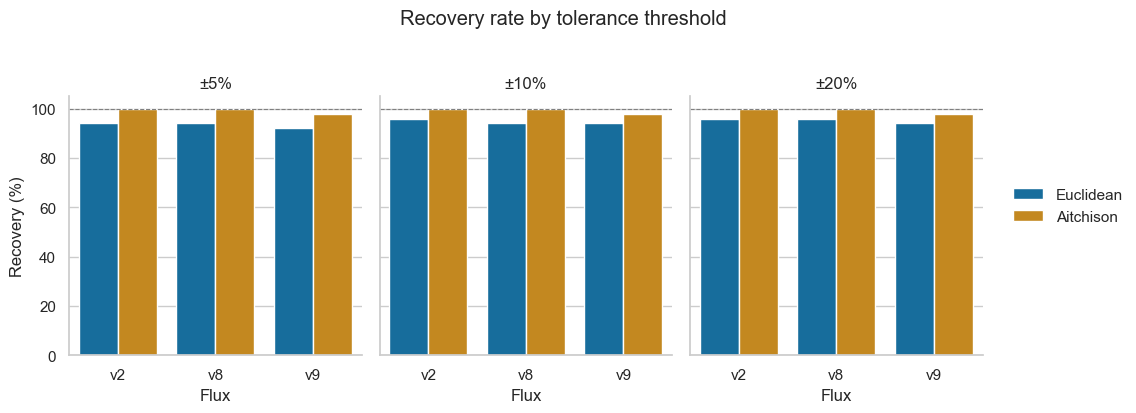

In [54]:
# ═══════════════════════════════════════════════════════════════════════════════
# 2. RECOVERY RATE — % of clean samples within ±5 %, ±10 %, ±20 % of true
# ═══════════════════════════════════════════════════════════════════════════════
tolerances = [0.05, 0.10, 0.20]
recovery_rows = []
for v in flux_vars:
    for method in ["Euclidean", "Aitchison"]:
        sub = df[(df["Flux"] == v) & (df["Method"] == method)]
        rel_err = (sub["Residual"] / sub["True"]).abs()
        for tol in tolerances:
            recovery_rows.append({
                "Flux": v, "Method": method,
                "Tolerance": f"±{int(tol*100)}%",
                "Recovery (%)": round(100 * (rel_err <= tol).mean(), 1),
            })

recovery_df = pd.DataFrame(recovery_rows)
recovery_pivot = recovery_df.pivot_table(
    index=["Flux", "Method"], columns="Tolerance", values="Recovery (%)"
)
print("Recovery rate (% of samples within relative tolerance of true flux):")
print(recovery_pivot.to_string())

g = sns.FacetGrid(recovery_df, col="Tolerance", height=4, aspect=0.85, sharey=True)
g.map_dataframe(sns.barplot, x="Flux", y="Recovery (%)", hue="Method",
                order=flux_vars, palette="colorblind", errorbar=None)
g.add_legend()
g.set_axis_labels("Flux", "Recovery (%)")
g.set_titles(col_template="{col_name}")
g.figure.suptitle("Recovery rate by tolerance threshold", y=1.03)
for ax in g.axes.flat:
    ax.set_ylim(0, 105)
    ax.axhline(100, color="grey", lw=0.8, ls="--")
g.tight_layout()
plt.show()